In [1]:
import keras
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [2]:
fashion_mnist = keras.datasets.fashion_mnist
(Xtrain, ytrain), (Xtest, ytest) = fashion_mnist.load_data()

In [3]:
Xtrain.shape

(60000, 28, 28)

In [4]:
Xtrain.dtype

dtype('uint8')

In [5]:
ytrain

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

> When dealing with the MNIST digit, when the label is equal to 5, it means that the image represents the handwritten digit 5. For Fashion MNIST, however, we need the list of class names to know what we are dealing with

In [6]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


In [7]:
class_names[ytrain[2]]

'T-shirt/top'

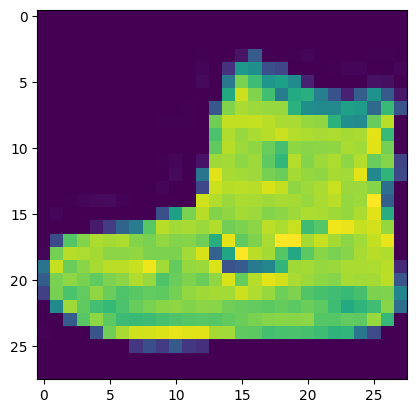

In [36]:
plt.imshow(Xtrain[0])

In [8]:
Xtrain = Xtrain / 255.0
Xtest = Xtest / 255.0

In [9]:
X_valid = Xtrain[:5000]
y_valid = ytrain[:5000]
X_train = Xtrain[5000:]
y_train = ytrain[5000:]

In [10]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=[28, 28]),
    keras.layers.Dense(300, activation='relu'),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

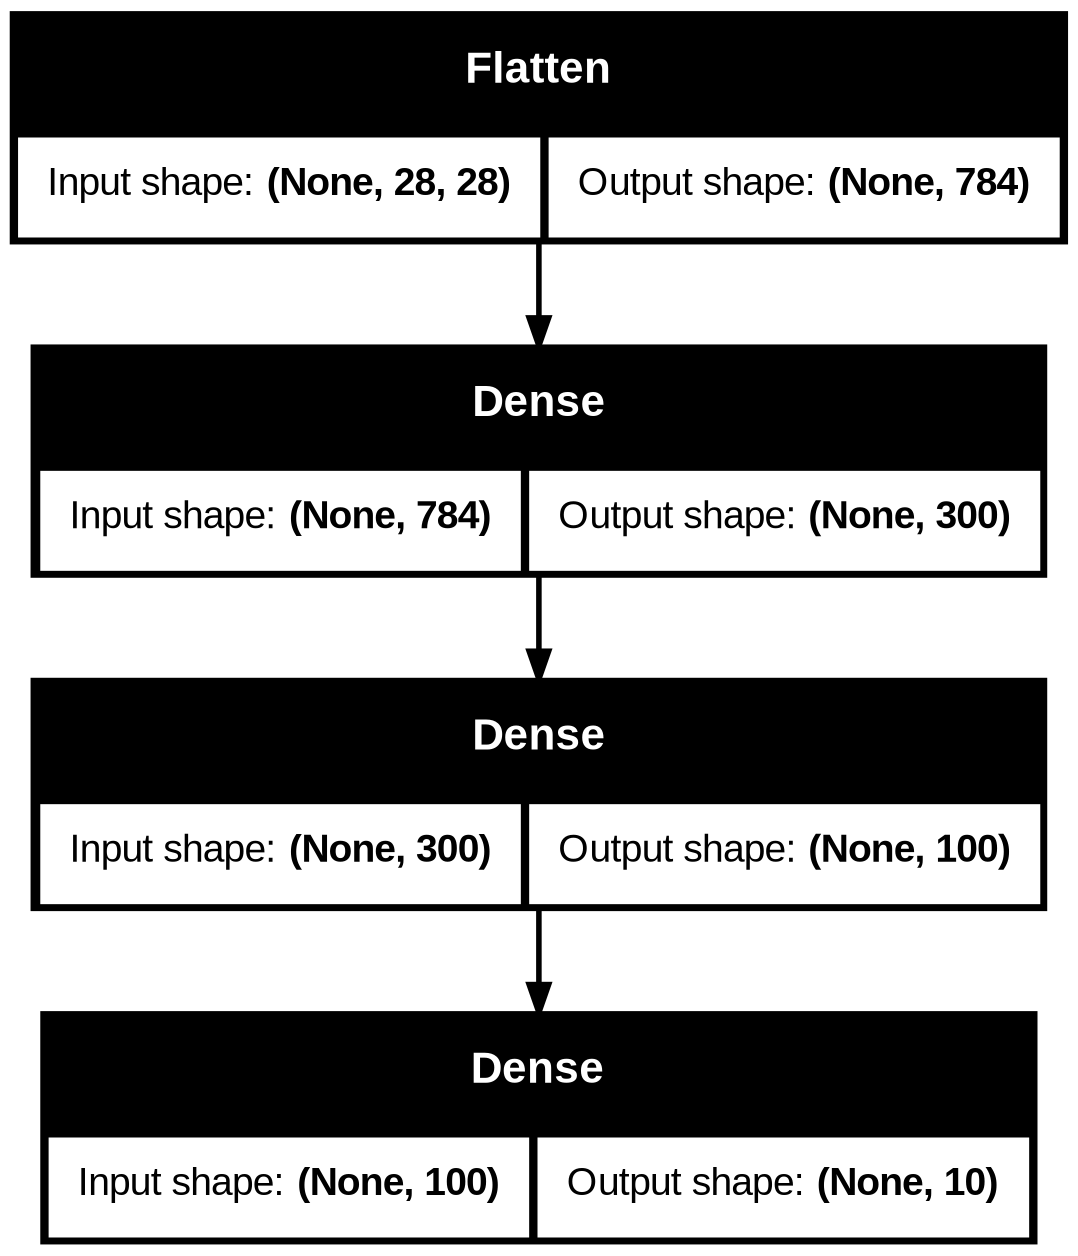

In [12]:
keras.utils.plot_model(model, show_shapes=True)

In [13]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [14]:
hidden2 = model.layers[2]
hidden2.name

'dense_1'

In [15]:
model.get_layer('dense_1') is hidden2

True

In [16]:
weights, biases = model.layers[1].get_weights()
print(f"weights shape: {weights.shape}")
print(f"biases shape: {biases.shape}")

weights shape: (784, 300)
biases shape: (300,)


In [17]:
weights

array([[ 0.06312834,  0.00045725,  0.07423845, ...,  0.00579742,
         0.04883946, -0.01040877],
       [-0.05163172,  0.03166487,  0.05887525, ...,  0.05341981,
        -0.01479898,  0.06213517],
       [-0.0328071 ,  0.06522977,  0.00111301, ..., -0.05538796,
         0.07234788, -0.05362921],
       ...,
       [ 0.03603679,  0.06735536, -0.0074215 , ..., -0.073502  ,
         0.03916678,  0.00451414],
       [-0.02651884, -0.06233022,  0.02413976, ...,  0.06691313,
         0.05992329, -0.07325931],
       [ 0.0364221 ,  0.04824487,  0.0026208 , ...,  0.0343054 ,
        -0.04172926, -0.05741018]], shape=(784, 300), dtype=float32)

In [18]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [19]:
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer = 'sgd',
    metrics = ['accuracy']
)

In [20]:
history = model.fit(
    Xtrain, ytrain,
    epochs = 30,
    validation_data = (X_valid, y_valid)
)

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7657 - loss: 0.7024 - val_accuracy: 0.8386 - val_loss: 0.4930
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8321 - loss: 0.4816 - val_accuracy: 0.8506 - val_loss: 0.4383
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8455 - loss: 0.4393 - val_accuracy: 0.8622 - val_loss: 0.4065
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8547 - loss: 0.4124 - val_accuracy: 0.8718 - val_loss: 0.3818
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8618 - loss: 0.3908 - val_accuracy: 0.8754 - val_loss: 0.3594
Epoch 6/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8682 - loss: 0.3758 - val_accuracy: 0.8780 - val_loss: 0.3526
Epoch 7/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8720 - loss: 0.3612 - val_accuracy: 0.8740 - val_loss: 0.3568
Epoch 8/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8758 - loss: 0.3493 - 

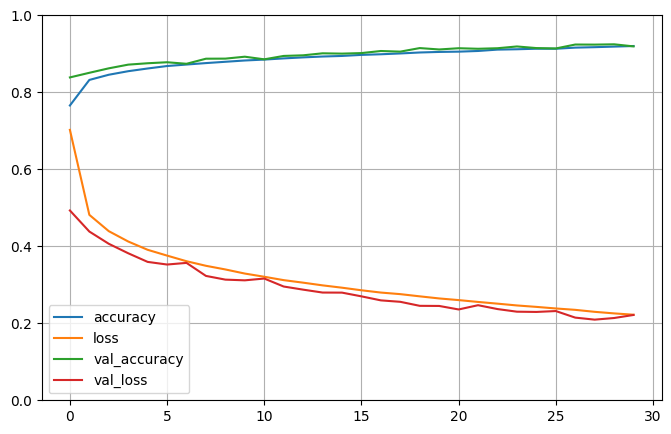

In [21]:
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()

In [22]:
model.evaluate(Xtest, ytest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8804 - loss: 0.3415


[0.3415219783782959, 0.8804000020027161]

In [29]:
Xnew = Xtest[:3]
ypred = model.predict(Xnew).argmax(axis=-1)
ypred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


array([9, 2, 1])

In [31]:
import numpy as np

np.array(class_names)[ypred]

array(['Ankle boot', 'Pullover', 'Trouser'], dtype='<U11')

In [33]:
ynew = ytest[:3]
ynew

array([9, 2, 1], dtype=uint8)

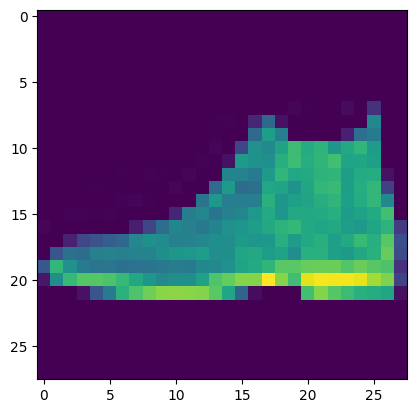

In [38]:
plt.imshow(Xtest[0])

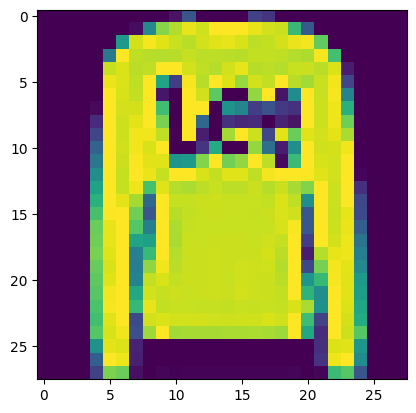

In [39]:
plt.imshow(Xtest[1])

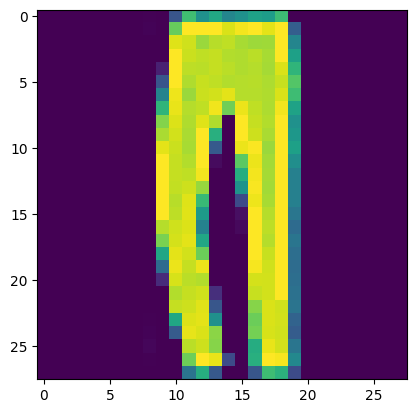

In [40]:
plt.imshow(Xtest[2])